# Training MLP 4 lớp — so sánh 3 phương pháp DSP

Bài toán **Normal / IR / OR / B**, sử dụng **28 đặc trưng** (11 Time + 10 Order + 7 Envelope). Ba bảng feature được tạo từ cùng manifest và cùng cửa sổ:

1. `hybrid`: I/Q vi phân + Alpha-Max-Beta-Min — phương pháp đề xuất.
2. `hilbert_offline`: FFT Hilbert toàn file — tham chiếu PC.
3. `hilbert_block`: FFT Hilbert theo block 2048 mẫu, float32 — mô phỏng phương pháp dự kiến port sang MCU.

Cả ba nhánh huấn luyện cùng một kiến trúc MLP và cùng fold/seed. Chỉ 7 đặc trưng Envelope được phép thay đổi; 11 Time + 10 Order phải giống nhau.

## Chỉ số báo cáo

| Chỉ số | Cách tính |
|---|---|
| **Accuracy** | Mức file (trung bình xác suất các cửa sổ của file); mean ± std qua seed, CI 95% bootstrap theo file |
| **Macro-F1** | Như trên; chỉ số chính |
| **Loss** | Training loss (cross-entropy + L2) theo epoch, kèm training accuracy; chỉ chẩn đoán hội tụ trên Train, không dùng chọn epoch |
| Confusion matrix | Tổng các seed, mức file (xem lớp bị nhầm) |

## Tổ chức code

Các hàm dùng lại được đặt trong **`src/mlp_experiment.py`**. Notebook chỉ cấu hình thí nghiệm, gọi hàm, hiển thị bảng/biểu đồ và ghi file kết quả.

## Giao thức

| Mục | Thiết kế |
|---|---|
| Cổng kiểm kê | 3 bảng feature cùng tập file/cửa sổ/thứ tự 28 cột; Time/Order giống nhau; CSV khớp Parquet; kiểm tra trùng tín hiệu và NaN/Inf |
| Stratified group k-fold | Nhóm theo `file_id`, phân tầng theo 10 lớp chi tiết (`class_label`), đánh giá 4 lớp (`label`) |
| Huấn luyện MLP | `28 → 32 → 16 → 4`, scaler fit riêng trên Train từng fold, epoch cố định, không early stopping |
| So sánh cặp | `Hybrid − Hilbert Offline` và `Hilbert Block − Hilbert Offline`, bootstrap ghép cặp theo file |
| Ablation | Chỉ trên Hybrid, bỏ lần lượt Time, Order, Envelope; báo cáo Accuracy, Macro-F1 và training loss |

**Lưu ý:** Hilbert Block trên PC là mô phỏng thuật toán dự kiến port sang MCU; đây chưa phải số đo chu kỳ/RAM/Flash trên STM32F4. Quét SNR và parity-check đã được gỡ khỏi notebook này (hàm vẫn còn trong `mlp_experiment.py`).


In [1]:
# CELL 1 — Môi trường & imports
import os
import json
import time
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn
from IPython.display import display

from src import config as cfg, dsp, features_full
from src import mlp_experiment as mlp_exp

print(
    f"Python {platform.python_version()} | numpy {np.__version__} | "
    f"pandas {pd.__version__} | sklearn {sklearn.__version__} | "
    f"tensorflow {tf.__version__}"
)


Python 3.11.9 | numpy 1.26.4 | pandas 3.0.3 | sklearn 1.9.0 | tensorflow 2.15.0


In [2]:
# CELL 2 — Cấu hình. CHỐT TRƯỚC khi chạy; không chỉnh theo kết quả Test.
FEATURES_DIR = os.path.abspath('../giai_doan_1_tien_xu_ly/outputs/tables')
# Tách thư mục kết quả để không ghi đè kết quả notebook 2 phương pháp phiên bản cũ.
OUTPUT_DIR = os.path.abspath('outputs/training_mlp_three_methods')

FEATURE_FILES = {
    'hybrid': 'features_mlp_hybrid',
    'hilbert_offline': 'features_mlp_hilbert',
    'hilbert_block': 'features_mlp_hilbert_block',
}
METHODS = ['hybrid', 'hilbert_offline', 'hilbert_block']
PRIMARY_METHOD = 'hybrid'                 # dùng cho ablation
REFERENCE_METHOD = 'hilbert_offline'       # tham chiếu cho so sánh cặp
METHOD_COMPARISONS = [
    ('hybrid', 'hilbert_offline'),
    ('hilbert_block', 'hilbert_offline'),
]

CLASS_NAMES = list(cfg.CLASSES_4)
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
LABEL_COL, GROUP_COL, STRAT_COL = 'label', 'file_id', 'class_label'

# --- Giao thức mục 6 ---
K = 4
SEEDS = list(range(42, 52))          # N = 10
FOLD_SOURCE_PREF = 'auto'            # 'auto' | 'manifest' | 'compute'
STRICT_MANIFEST_HASH = True

# --- MLP: cố định trước. Không Val, không early stopping ---
EPOCHS = 40
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MLP_KWARGS = dict(hidden_units=(32, 16), dropout_rate=0.1, l2_reg=1e-4)
USE_CLASS_WEIGHT = False

# --- Bootstrap theo file ---
N_BOOT = 2000
BOOT_SEED = 20240
CI_ALPHA = 0.05
NONINFERIORITY_MARGIN = None         # chỉ áp dụng cho Hybrid so với Hilbert Offline khi đã chốt

# --- Ablation (chỉ trên PRIMARY_METHOD) ---
RUN_ABLATION = True
ABLATION_SEEDS = SEEDS[:3]

# --- Ghi nhận cấu hình DSP vào run_config.json (phải trùng notebook 05) ---
TARGET_FS_HZ = cfg.SCOPE['sampling_rate_hz']
BAND_HZ = dsp.BENCHMARK_BAND_HZ
LP_CUTOFF_HZ = cfg.LP_CUTOFF_HZ
BANDPASS_ORDER = dsp.BENCHMARK_BANDPASS_ORDER
LOWPASS_ORDER = dsp.BENCHMARK_LOWPASS_ORDER
WINDOW_SIZE = cfg.WINDOW_SIZE_RAW
STRIDE = cfg.STRIDE_RAW
HILBERT_BLOCK_KWARGS = {
    'block_size': int(getattr(dsp, 'HILBERT_BLOCK_SIZE', WINDOW_SIZE)),
    'float32': True,
    'align_delay': True,
}

# --- Màu/nét dùng chung cho mọi hình (bảng màu đã kiểm tra phân biệt được khi mù màu) ---
METHOD_COLORS = {
    'hybrid': '#2a78d6',
    'hilbert_offline': '#52514e',
    'hilbert_block': '#eb6834',
}
LINE_STYLE = {
    'hybrid': dict(linestyle='-', linewidth=3.0, zorder=3),
    'hilbert_offline': dict(linestyle=(0, (4, 3)), linewidth=2.0, zorder=4),
    'hilbert_block': dict(linestyle=(0, (1, 2)), linewidth=2.2, zorder=5),
}

assert PRIMARY_METHOD in METHODS
assert REFERENCE_METHOD in METHODS
assert set(METHODS) == set(FEATURE_FILES) == set(METHOD_COLORS)
assert len(set(SEEDS)) == len(SEEDS)
assert set(ABLATION_SEEDS) <= set(SEEDS), 'ABLATION_SEEDS phải nằm trong SEEDS để so ghép cặp với lần chạy chính.'
assert WINDOW_SIZE == HILBERT_BLOCK_KWARGS['block_size'], (
    f'WINDOW_SIZE={WINDOW_SIZE} phải trùng Hilbert block_size={HILBERT_BLOCK_KWARGS["block_size"]}.'
)
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'Features: {FEATURES_DIR}\nOutput  : {OUTPUT_DIR}')
print(f'Classes: {CLASS_NAMES}; K={K}; seeds={SEEDS[0]}–{SEEDS[-1]} (N={len(SEEDS)}); '
      f'epochs={EPOCHS}; methods={METHODS}')


Features: f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_1_tien_xu_ly\outputs\tables
Output  : f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_2_model\outputs\training_mlp_three_methods
Classes: ['Normal', 'IR', 'OR', 'B']; K=4; seeds=42–51 (N=10); epochs=40; methods=['hybrid', 'hilbert_offline', 'hilbert_block']


## 1. Đọc ba bảng đặc trưng và cổng kiểm kê

Notebook chỉ chạy khi:

- mỗi lớp chi tiết (`class_label`, 10 lớp) có ít nhất `k` file;
- ba bảng `features_mlp_hybrid`, `features_mlp_hilbert`, `features_mlp_hilbert_block` có cùng tập file/cửa sổ, cùng thứ tự 28 cột;
- 21 đặc trưng Time + Order giống nhau giữa cả ba nhánh; chỉ 7 đặc trưng Envelope được phép khác;
- `dsp_method` trong từng bảng đúng với phương pháp tương ứng;
- CSV và Parquet của cùng bảng khớp nhau nếu cả hai cùng tồn tại;
- không có hai file chứa cùng một tín hiệu và không có NaN/Inf trong feature.

Nhãn huấn luyện là 4 lớp `label` (Normal/IR/OR/B); phân tầng fold vẫn dùng `class_label` 10 lớp chi tiết để giữ cân bằng theo đường kính lỗi.


In [3]:
# CELL 3 — Nạp bảng + cổng kiểm kê (logic nằm trong src/mlp_experiment.py)
audit = mlp_exp.load_and_audit_feature_tables(
    FEATURES_DIR,
    FEATURE_FILES,
    METHODS,
    PRIMARY_METHOD,
    CLASS_NAMES,
    K,
    TARGET_FS_HZ,
    group_col=GROUP_COL,
    label_col=LABEL_COL,
    strat_col=STRAT_COL,
    expected_feature_count=28,
    expected_groups=(11, 10, 7),
)

feature_tables = audit["feature_tables"]
TABLE_PATHS = audit["table_paths"]
TABLE_SHA256 = audit["table_sha256"]
FEATURE_COLS = audit["feature_cols"]
TIME_COLS = audit["time_cols"]
ORDER_COLS = audit["order_cols"]
ENV_COLS = audit["env_cols"]
file_meta = audit["file_meta"]
files_per_class = audit["files_per_class"]
files_per_label = audit["files_per_label"]
ALL_FILES = audit["all_files"]
STRAT_BY_FILE = audit["strat_by_file"]
LABEL_BY_FILE = audit["label_by_file"]
ref = feature_tables[PRIMARY_METHOD]

print("Số file theo 10 lớp chi tiết:")
display(files_per_class.to_frame().T)
print("Số file theo 4 nhãn:")
display(files_per_label.to_frame().T)
print("Cửa sổ/lớp:", ref.groupby(LABEL_COL).size().reindex(CLASS_NAMES).to_dict())

if not audit["provenance_review"].empty:
    print("File có fs nguồn khác target fs hoặc RPM không đo trực tiếp (ghi nhận trong báo cáo):")
    display(audit["provenance_review"])

print(
    f"Cổng kiểm kê: ĐẠT ({len(file_meta)} file, {len(ref)} cửa sổ, "
    f"{len(FEATURE_COLS)} đặc trưng, {len(METHODS)} phương pháp)."
)


Số file theo 10 lớp chi tiết:


class_label,B_007,B_014,B_021,IR_007,IR_014,IR_021,Normal,OR_007,OR_014,OR_021
Số file,4,4,4,4,4,4,4,4,4,4


Số file theo 4 nhãn:


,Normal,IR,OR,B
Số file,4,12,12,12


Cửa sổ/lớp: {'Normal': 401, 'IR': 1386, 'OR': 1389, 'B': 1387}
File có fs nguồn khác target fs hoặc RPM không đo trực tiếp (ghi nhận trong báo cáo):


,file_id,label,class_label,n_windows,load_hp,fault_diameter_mils,rpm,rpm_source,source_sample_rate_hz,source_sample_rate_source
0,100_Normal_3,Normal,Normal,115,3,NaN,1725.0,measured,48000.0,inferred:sample_count_and_expected_duration
37,97_Normal_0,Normal,Normal,56,0,NaN,1796.0,measured,48000.0,file_catalog:user_reviewed
38,98_Normal_1,Normal,Normal,115,1,NaN,1772.0,imputed:nominal_by_load,48000.0,inferred:sample_count_and_expected_duration
39,99_Normal_2,Normal,Normal,115,2,NaN,1750.0,imputed:nominal_by_load,48000.0,inferred:sample_count_and_expected_duration


Cổng kiểm kê: ĐẠT (40 file, 4563 cửa sổ, 28 đặc trưng, 3 phương pháp).


## 2. Tạo fold dùng chung

Phân tầng theo **10 lớp chi tiết** (`class_label`, dự kiến 4 file/lớp), nhưng huấn luyện/đánh giá **4 lớp** (`label`: Normal/IR/OR/B). Với `k = 4`, mỗi fold Test có một file của mỗi lớp chi tiết nếu kiểm kê thỏa điều kiện. Ba phương pháp sử dụng chung chính xác danh sách file Train/Test theo từng seed và fold.


In [4]:
# CELL 4 — Tạo fold dùng chung (logic nằm trong src/mlp_experiment.py)
fold_result = mlp_exp.build_group_folds(
    file_meta,
    FEATURES_DIR,
    OUTPUT_DIR,
    SEEDS,
    K,
    CLASS_NAMES,
    fold_source_preference=FOLD_SOURCE_PREF,
    strict_manifest_hash=STRICT_MANIFEST_HASH,
    group_col=GROUP_COL,
    label_col=LABEL_COL,
    strat_col=STRAT_COL,
)

FOLDS = fold_result["folds"]
FOLD_SOURCE = fold_result["fold_source"]
fold_audit = fold_result["fold_audit"]
print(f"Nguồn fold: {FOLD_SOURCE}")
print(f"Kiểm tra fold: ĐẠT ({len(SEEDS)} seed × {K} fold; mỗi file test đúng 1 lần/seed).")
display(fold_result["fold_summary"])


Nguồn fold: manifest_with_folds.csv
Kiểm tra fold: ĐẠT (10 seed × 4 fold; mỗi file test đúng 1 lần/seed).


,fold,n_train_files,n_test_files,test_Normal,train_Normal,test_IR,train_IR,test_OR,train_OR,test_B,train_B
0,1,30,10,1,3,3,9,3,9,3,9
1,2,30,10,1,3,3,9,3,9,3,9
2,3,30,10,1,3,3,9,3,9,3,9
3,4,30,10,1,3,3,9,3,9,3,9


## 3. Huấn luyện MLP theo fold — ba phương pháp

Mỗi (phương pháp, seed, fold): `StandardScaler` fit **chỉ trên Train**, MLP cố định `28 → 32 → 16 → 4` (softmax), `EPOCHS` cố định, **không Val, không early stopping**. Khởi tạo mô hình dùng seed `seed*100 + fold`, giống nhau giữa ba phương pháp để so sánh cặp.

Dự đoán cấp file = trung bình xác suất của các cửa sổ thuộc cùng `file_id`. Với 3 phương pháp × 10 seed × 4 fold = **120 lượt huấn luyện**. Mỗi epoch ghi lại training loss và training accuracy vào `CURVE_ROWS` (dùng cho mục 3.1).


In [5]:
# CELL 5 — Huấn luyện/đánh giá theo fold (logic nằm trong src/mlp_experiment.py)
CURVE_ROWS = []   # learning curve: method, variant, seed, fold, epoch, loss, accuracy

RUN_T0 = time.time()
prediction_parts = []
for method in METHODS:
    print(f"== {method} ==")
    cv_result = mlp_exp.run_cross_validation(
        method,
        feature_tables[method],
        FEATURE_COLS,
        SEEDS,
        FOLDS,
        CLASS_NAMES,
        CLASS_TO_ID,
        MLP_KWARGS,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE,
        use_class_weight=USE_CLASS_WEIGHT,
        keep_state=False,
        group_col=GROUP_COL,
        label_col=LABEL_COL,
    )
    prediction_parts.append(cv_result["predictions"])
    CURVE_ROWS.extend(cv_result["learning_curves"])

predictions_df = pd.concat(prediction_parts, ignore_index=True)
CV_SECONDS = time.time() - RUN_T0

# Mỗi (phương pháp, seed) phải có đúng một dự đoán cho từng file.
for (method, seed), group in predictions_df.groupby(["method", "seed"]):
    if sorted(group["file_id"].astype(str)) != ALL_FILES:
        raise RuntimeError(f"{method}/seed {seed}: mỗi file phải có đúng một dự đoán Test.")
print(f"Xong {len(predictions_df)} dự đoán mức file trong {CV_SECONDS / 60:.1f} phút.")


== hybrid ==



  hybrid               seed 42 xong (   23s)
  hybrid               seed 43 xong (   44s)
  hybrid               seed 44 xong (   65s)
  hybrid               seed 45 xong (   86s)
  hybrid               seed 46 xong (  107s)
  hybrid               seed 47 xong (  128s)
  hybrid               seed 48 xong (  149s)
  hybrid               seed 49 xong (  171s)
  hybrid               seed 50 xong (  192s)
  hybrid               seed 51 xong (  213s)
== hilbert_offline ==
  hilbert_offline      seed 42 xong (   22s)
  hilbert_offline      seed 43 xong (   44s)
  hilbert_offline      seed 44 xong (   66s)
  hilbert_offline      seed 45 xong (   87s)
  hilbert_offline      seed 46 xong (  110s)
  hilbert_offline      seed 47 xong (  131s)
  hilbert_offline      seed 48 xong (  153s)
  hilbert_offline      seed 49 xong (  175s)
  hilbert_offline      seed 50 xong (  197s)
  hilbert_offline      seed 51 xong (  218s)
== hilbert_block ==
  hilbert_block        seed 42 xong (   22

### 3.1 Loss — Training Loss / Training Accuracy theo epoch

Đường đậm là trung bình qua các mô hình (seed × fold), vùng tô là ±1 std, đường mảnh là từng mô hình. Đây chỉ là chẩn đoán hội tụ trên Train; **không** dùng để chọn epoch dựa trên Test. Ba nhánh dùng chung 21 đặc trưng Time + Order; chỉ 7 đặc trưng Envelope khác nhau.


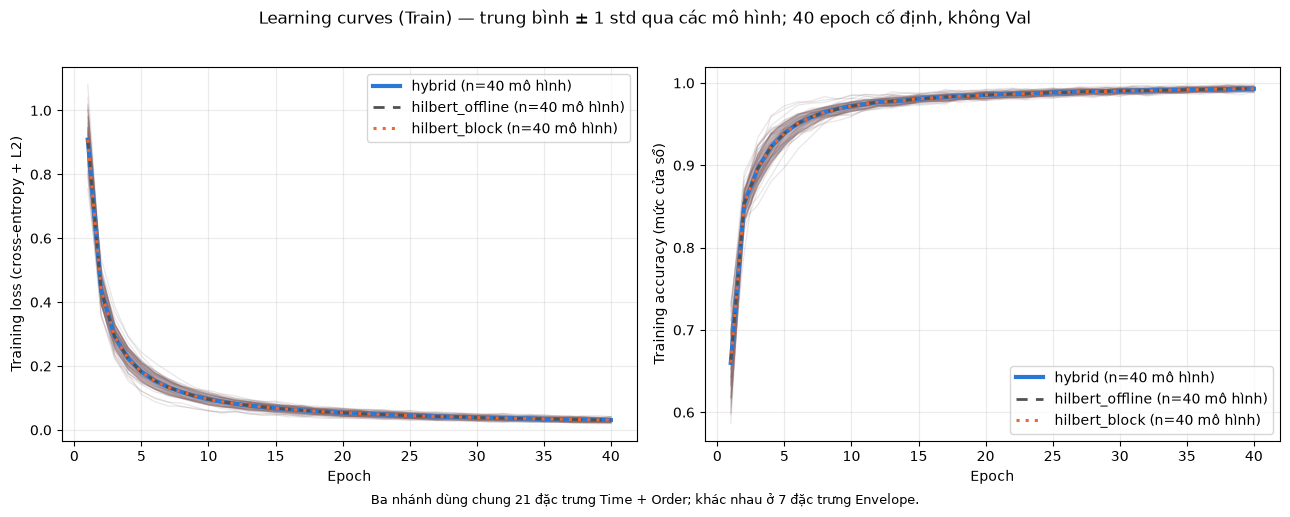

,method,n_models,loss_epoch_1,loss_last_mean,loss_last_std,acc_last_mean,acc_last_std,loss_drop_last_epochs_pct,tail_epochs
0,hybrid,40,0.9086,0.0311,0.0060,0.9930,0.0025,19.2748,10
1,hilbert_offline,40,0.9083,0.0311,0.0060,0.9929,0.0025,19.2266,10
2,hilbert_block,40,0.9083,0.0310,0.0059,0.9930,0.0024,19.4139,10


Nếu loss vẫn giảm rõ ở các epoch cuối, mô hình chưa hội tụ hẳn trên Train.


In [6]:
# CELL 6 — Learning curves: Training Loss / Training Accuracy
learning_curves = pd.DataFrame(CURVE_ROWS)
main_curves = learning_curves[learning_curves['variant'] == 'All 28 features'].copy()
n_models = {m: int(main_curves[main_curves['method'] == m][['seed', 'fold']].drop_duplicates().shape[0])
            for m in METHODS}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, metric, ylabel in ((axes[0], 'loss', 'Training loss (cross-entropy + L2)'),
                           (axes[1], 'accuracy', 'Training accuracy (mức cửa sổ)')):
    for method in METHODS:
        g = main_curves[main_curves['method'] == method]
        for _, curve in g.groupby(['seed', 'fold']):
            ax.plot(curve['epoch'], curve[metric], color=METHOD_COLORS[method], alpha=0.06, linewidth=0.8)
        agg = g.groupby('epoch')[metric].agg(['mean', 'std'])
        ax.plot(agg.index, agg['mean'], color=METHOD_COLORS[method],
                label=f'{method} (n={n_models[method]} mô hình)', **LINE_STYLE[method])
        ax.fill_between(agg.index, agg['mean'] - agg['std'], agg['mean'] + agg['std'],
                        color=METHOD_COLORS[method], alpha=0.18)
    ax.set_xlabel('Epoch')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend()
fig.suptitle(f'Learning curves (Train) — trung bình ± 1 std qua các mô hình; {EPOCHS} epoch cố định, không Val', y=1.02)
fig.text(0.5, -0.01, 'Ba nhánh dùng chung 21 đặc trưng Time + Order; khác nhau ở 7 đặc trưng Envelope.',
         ha='center', fontsize=9)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'learning_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

# Chẩn đoán hội tụ trên Train (mô tả, không dùng để chỉnh theo Test)
curve_summary = mlp_exp.summarize_learning_curves(main_curves.to_dict('records'), ('method',)) # type: ignore
learning_curve_diag = mlp_exp.final_epoch_table(main_curves, ('method',))
display(learning_curve_diag.round(4))
print('Nếu loss vẫn giảm rõ ở các epoch cuối, mô hình chưa hội tụ hẳn trên Train.')


## 4. Báo cáo mức file

- **Theo seed**: Accuracy và Macro-F1 gộp theo file qua `k` fold (mỗi file đúng một lần), rồi mean ± std qua N seed.
- **Bất định**: CI 95% bootstrap theo file; cùng một ma trận chỉ số file được dùng cho tất cả phương pháp để giữ tính ghép cặp.
- **So sánh chính**: `Hybrid − Hilbert Offline` và `Hilbert Block − Hilbert Offline`, cùng tham chiếu phân loại là FFT Hilbert toàn file. Delta dương nghĩa là ứng viên có chỉ số cao hơn tham chiếu.
- **Non-inferiority**: ngưỡng chỉ được kiểm tra cho `Hybrid − Hilbert Offline` khi `NONINFERIORITY_MARGIN` đã được chốt trước.
- Với 40 file, một file tương ứng 2,5 điểm phần trăm Accuracy; số file ít khiến CI có độ phân giải thô.


In [7]:
# CELL 6 — Thống kê mức file + bootstrap theo file (logic nằm trong src/mlp_experiment.py)
K_CLS = len(CLASS_NAMES)
N_FILES = len(ALL_FILES)
BOOT_IDX = mlp_exp.make_bootstrap_indices(N_FILES, N_BOOT, BOOT_SEED)

metric_result = mlp_exp.evaluate_clean_predictions(
    predictions_df,
    METHODS,
    METHOD_COMPARISONS,
    PRIMARY_METHOD,
    ALL_FILES,
    CLASS_NAMES,
    BOOT_IDX,
    alpha=CI_ALPHA,
    noninferiority_margin=NONINFERIORITY_MARGIN,
)
main = metric_result["main"]
summary = metric_result["summary"]
metrics_by_seed = metric_result["metrics_by_seed"]
delta_table = metric_result["delta_table"]
recall_table = metric_result["recall_table"]
error_table = metric_result["error_table"]
print("Đã tính xong thống kê mức file cho ba phương pháp.")


Đã tính xong thống kê mức file cho ba phương pháp.


Accuracy / Macro-F1 mức file: mean ± std qua seed và CI 95% bootstrap theo file


,method,accuracy_mean,accuracy_std_seeds,accuracy_ci_lo,accuracy_ci_hi,macro_f1_mean,macro_f1_std_seeds,macro_f1_ci_lo,macro_f1_ci_hi,n_files,n_seeds
0,hybrid,0.9175,0.029,0.8325,0.9825,0.9137,0.0343,0.8099,0.9807,40,10
1,hilbert_offline,0.9175,0.029,0.8325,0.9825,0.9137,0.0343,0.8099,0.9807,40,10
2,hilbert_block,0.9175,0.029,0.8325,0.9825,0.9137,0.0343,0.8099,0.9807,40,10



Theo từng seed (mỗi seed = 40 file, mỗi file test đúng một lần):


method,acc_hybrid,acc_hilbert_offline,acc_hilbert_block,f1_hybrid,f1_hilbert_offline,f1_hilbert_block
seed,,,,,,
42,0.925,0.925,0.925,0.9195,0.9195,0.9195
43,0.950,0.950,0.950,0.9395,0.9395,0.9395
44,0.925,0.925,0.925,0.9195,0.9195,0.9195
45,0.925,0.925,0.925,0.9194,0.9194,0.9194
46,0.950,0.950,0.950,0.9580,0.9580,0.9580
47,0.900,0.900,0.900,0.9002,0.9002,0.9002
48,0.875,0.875,0.875,0.8664,0.8664,0.8664
49,0.900,0.900,0.900,0.9002,0.9002,0.9002
50,0.875,0.875,0.875,0.8566,0.8566,0.8566



Hiệu số cặp (ứng viên − hilbert_offline), CI 95% bootstrap theo file:


,candidate,reference,delta_accuracy,delta_accuracy_ci_lo,delta_accuracy_ci_hi,delta_macro_f1,delta_macro_f1_ci_lo,delta_macro_f1_ci_hi,n_replicates,n_files
0,hybrid,hilbert_offline,0.0,0.0,0.0,0.0,0.0,0.0,10,40
1,hilbert_block,hilbert_offline,0.0,0.0,0.0,0.0,0.0,0.0,10,40


Biên non-inferiority chưa chốt: không đưa ra kết luận đạt/không đạt H2b.


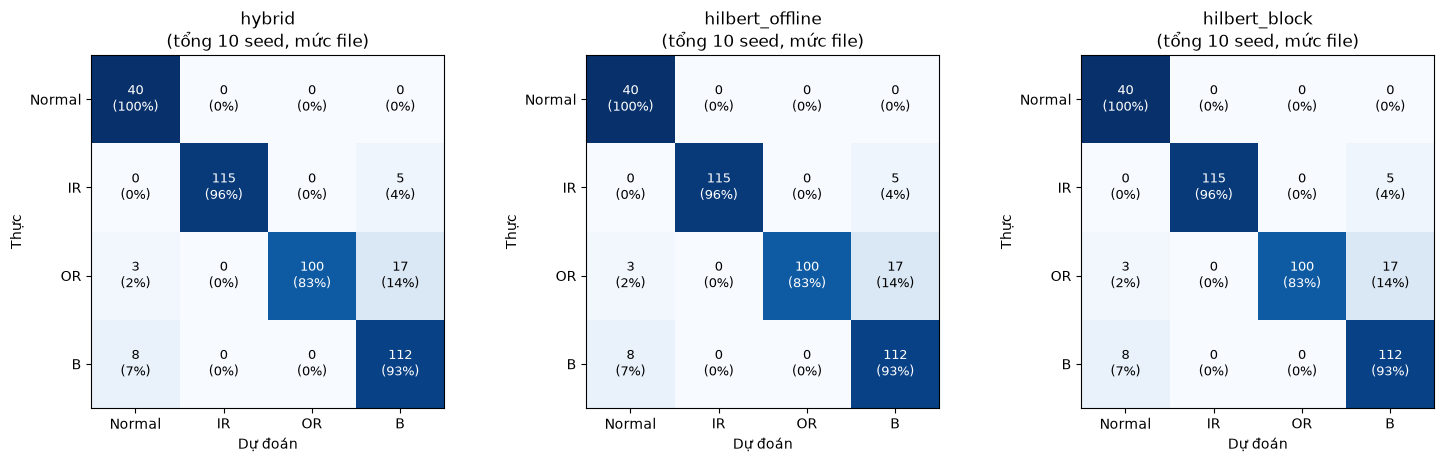

In [8]:
# CELL 8 — Hiển thị Accuracy / Macro-F1 mức file
print('Accuracy / Macro-F1 mức file: mean ± std qua seed và CI 95% bootstrap theo file')
display(summary.round(4))

print('\nTheo từng seed (mỗi seed = 40 file, mỗi file test đúng một lần):')
display(metrics_by_seed.pivot(index='seed', columns='method', values='accuracy')[METHODS].round(4)
        .rename(columns=lambda c: f'acc_{c}')
        .join(metrics_by_seed.pivot(index='seed', columns='method', values='macro_f1')[METHODS].round(4)
              .rename(columns=lambda c: f'f1_{c}')))

print(f'\nHiệu số cặp (ứng viên − {REFERENCE_METHOD}), CI 95% bootstrap theo file:')
display(delta_table.round(4))
if NONINFERIORITY_MARGIN is None:
    print('Biên non-inferiority chưa chốt: không đưa ra kết luận đạt/không đạt H2b.')

# --- Confusion matrix: tổng các CM theo seed (mỗi file xuất hiện N_seed lần; KHÔNG phải ensemble) ---
fig, axes = plt.subplots(1, len(METHODS), figsize=(5.0 * len(METHODS), 4.6))
for ax, method in zip(np.atleast_1d(axes), METHODS):
    cm = main['cm'][method]
    norm = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(norm, vmin=0, vmax=1, cmap='Blues')
    for i in range(K_CLS):
        for j in range(K_CLS):
            ax.text(j, i, f'{cm[i, j]}\n({norm[i, j]:.0%})', ha='center', va='center',
                    color='white' if norm[i, j] > 0.5 else 'black', fontsize=9)
    ax.set_xticks(range(K_CLS), CLASS_NAMES)
    ax.set_yticks(range(K_CLS), CLASS_NAMES)
    ax.set_xlabel('Dự đoán')
    ax.set_ylabel('Thực')
    ax.set_title(f'{method}\n(tổng {len(SEEDS)} seed, mức file)')
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'confusion_matrices.png'), dpi=150, bbox_inches='tight')
plt.show()


### 4.1 So sánh ba phương pháp và hai hiệu số theo cặp

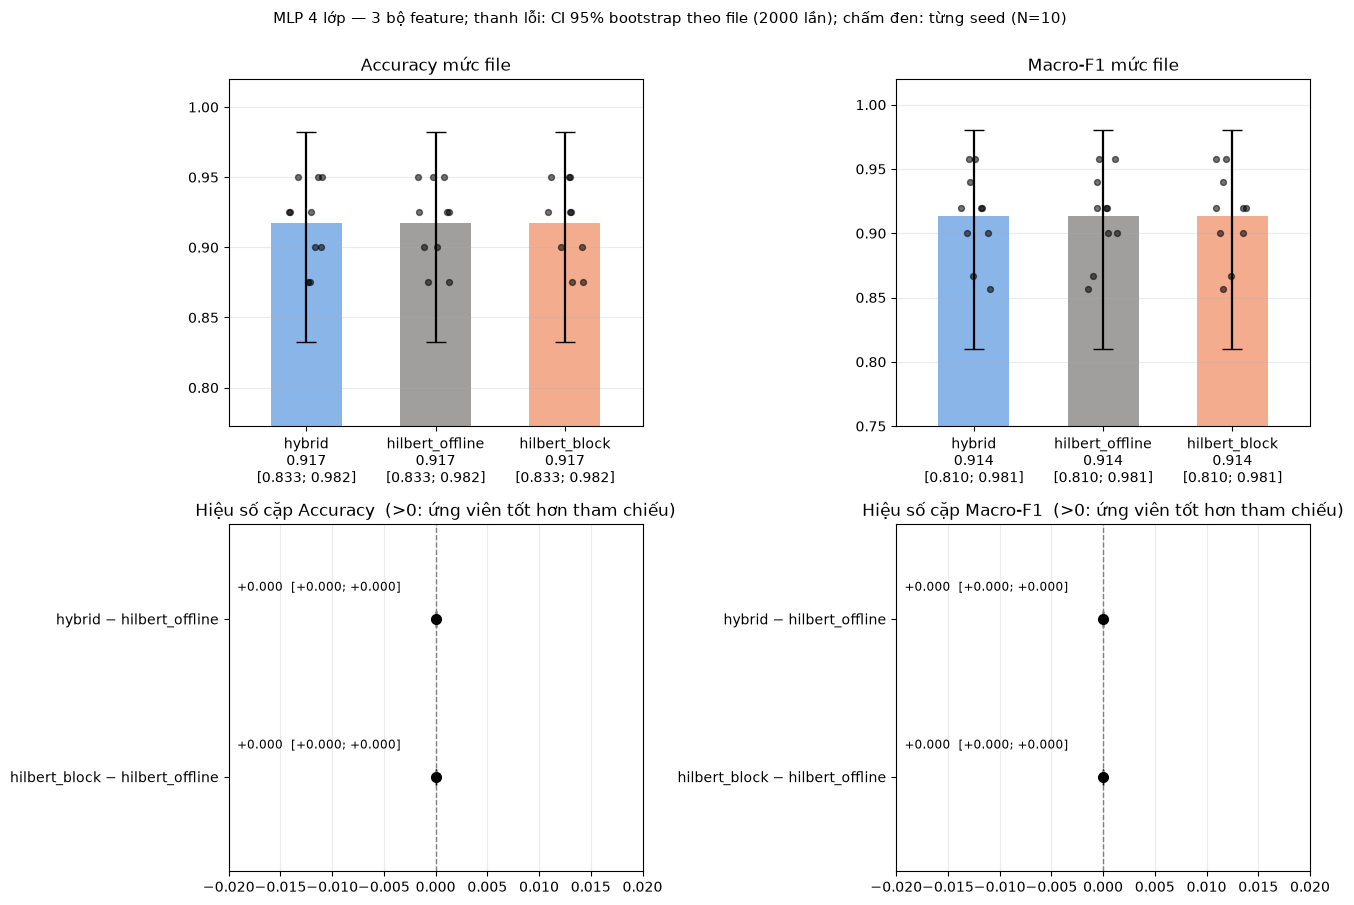

In [9]:
# CELL 9 — So sánh ba phương pháp và hai hiệu số ứng viên − Hilbert Offline
sm = summary.set_index('method').loc[METHODS]
jitter = np.random.default_rng(0)
x = np.arange(len(METHODS))

fig, axes = plt.subplots(2, 2, figsize=(13.5, 9))
for ax, metric, title in ((axes[0, 0], 'accuracy', 'Accuracy mức file'),
                          (axes[0, 1], 'macro_f1', 'Macro-F1 mức file')):
    mean = sm[f'{metric}_mean'].to_numpy()
    lo, hi = sm[f'{metric}_ci_lo'].to_numpy(), sm[f'{metric}_ci_hi'].to_numpy()
    ax.bar(x, mean, color=[METHOD_COLORS[m] for m in METHODS], alpha=0.55, width=0.55)
    ax.errorbar(x, mean, yerr=np.vstack([mean - lo, hi - mean]), fmt='none',
                ecolor='black', capsize=7, linewidth=1.6)
    for i, method in enumerate(METHODS):
        vals = metrics_by_seed[metrics_by_seed['method'] == method][metric].to_numpy()
        ax.scatter(i + jitter.uniform(-0.14, 0.14, len(vals)), vals,
                   s=18, color='black', alpha=0.55, zorder=3)
    low_bound = min(lo.min(), metrics_by_seed[metric].min())
    ax.set_ylim(max(0.0, low_bound - 0.06), 1.02)
    ax.set_xlim(-0.6, len(METHODS) - 0.4)
    ax.set_xticks(x, [f'{m}\n{mean[i]:.3f}\n[{lo[i]:.3f}; {hi[i]:.3f}]'
                      for i, m in enumerate(METHODS)])
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.25)

pairs = list(zip(delta_table['candidate'], delta_table['reference']))
ypos = np.arange(len(pairs))[::-1]
for ax, name, title in ((axes[1, 0], 'accuracy', 'Hiệu số cặp Accuracy'),
                        (axes[1, 1], 'macro_f1', 'Hiệu số cặp Macro-F1')):
    d = delta_table[f'delta_{name}'].to_numpy()
    lo = delta_table[f'delta_{name}_ci_lo'].to_numpy()
    hi = delta_table[f'delta_{name}_ci_hi'].to_numpy()
    ax.errorbar(d, ypos, xerr=np.vstack([d - lo, hi - d]),
                fmt='o', color='black', capsize=6, markersize=7)
    ax.axvline(0, color='gray', linestyle='--', linewidth=1)
    for yi, di, loi, hii in zip(ypos, d, lo, hi):
        ax.text(0.02, yi + 0.16, f'{di:+.3f}  [{loi:+.3f}; {hii:+.3f}]',
                transform=ax.get_yaxis_transform(), fontsize=8.5, va='bottom')
    bound = max(0.02, float(np.nanmax(np.abs(np.concatenate([lo, hi])))) * 1.8)
    ax.set_xlim(-bound, bound)
    ax.set_ylim(-0.6, len(pairs) - 0.4)
    ax.set_yticks(ypos, [f'{c} − {r}' for c, r in pairs])
    ax.set_title(title + '  (>0: ứng viên tốt hơn tham chiếu)')
    ax.grid(axis='x', alpha=0.25)

fig.suptitle(
    f'MLP 4 lớp — 3 bộ feature; thanh lỗi: CI 95% bootstrap theo file '
    f'({N_BOOT} lần); chấm đen: từng seed (N={len(SEEDS)})',
    y=1.0, fontsize=11
)
plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, 'compare_methods_ci.png'), dpi=150, bbox_inches='tight')
plt.show()


## 5. Ablation theo nhóm đặc trưng

Chỉ chạy khi `RUN_ABLATION = True`, trên `PRIMARY_METHOD = 'hybrid'` đã khai báo trước, lần lượt bỏ Time, Order hoặc Envelope; cùng seed/fold/khởi tạo với lần chạy chính nên so ghép cặp được. Báo cáo Accuracy, Macro-F1 (mức file) và training loss ở epoch cuối. `Δ = All − Without` kèm CI bootstrap theo file. Kết quả mang tính mô tả, không dùng để chọn mô hình theo Test.


Ablation: bỏ Time-domain -> 17 đặc trưng
  hybrid               seed 42 xong (   22s)
  hybrid               seed 43 xong (   44s)
  hybrid               seed 44 xong (   66s)
Ablation: bỏ Order/frequency -> 18 đặc trưng
  hybrid               seed 42 xong (   21s)
  hybrid               seed 43 xong (   43s)
  hybrid               seed 44 xong (   64s)
Ablation: bỏ Envelope -> 21 đặc trưng
  hybrid               seed 42 xong (   21s)
  hybrid               seed 43 xong (   43s)
  hybrid               seed 44 xong (   65s)


,variant,n_features,accuracy_mean,accuracy_std_seeds,accuracy_ci_lo,accuracy_ci_hi,macro_f1_mean,macro_f1_std_seeds,macro_f1_ci_lo,macro_f1_ci_hi,n_files,n_seeds,n_models,loss_epoch_1,loss_last_mean,loss_last_std,acc_last_mean,acc_last_std
0,All 28 features,28,0.9333,0.0144,0.8500,1.0000,0.9262,0.0115,0.8121,1.000,40,3,12,0.9199,0.0298,0.0059,0.9935,0.0026
1,Without Time-domain,17,0.9667,0.0144,0.9083,1.0000,0.9639,0.0264,0.8919,1.000,40,3,12,1.0140,0.0626,0.0125,0.9815,0.0040
2,Without Order/frequency,18,0.9333,0.0144,0.8500,1.0000,0.9390,0.0013,0.8459,1.000,40,3,12,0.9429,0.0644,0.0227,0.9811,0.0091
3,Without Envelope,21,0.8750,0.0250,0.7750,0.9583,0.8712,0.0213,0.7249,0.958,40,3,12,1.0098,0.0455,0.0067,0.9887,0.0027


Độ sụt giảm (All − Without), CI 95% bootstrap theo file:


,reference,versus,delta_accuracy,delta_accuracy_ci_lo,delta_accuracy_ci_hi,delta_macro_f1,delta_macro_f1_ci_lo,delta_macro_f1_ci_hi
0,All 28 features,Without Time-domain,-0.0333,-0.100,0.0167,-0.0377,-0.1468,0.0355
1,All 28 features,Without Order/frequency,0.0000,-0.075,0.0750,-0.0129,-0.0864,0.0542
2,All 28 features,Without Envelope,0.0583,-0.000,0.1417,0.0549,-0.0146,0.1542


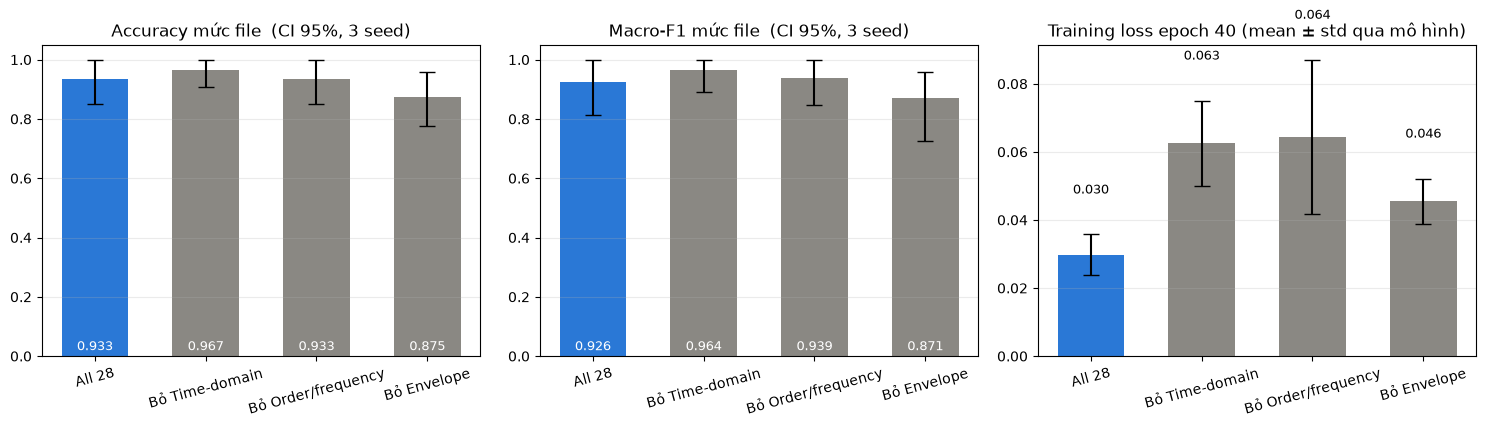

In [10]:
# CELL 10 — Ablation trên Hybrid: Accuracy, Macro-F1, Loss
ablation = None
ablation_table = None
if RUN_ABLATION:
    groups = {
        "Time-domain": TIME_COLS,
        "Order/frequency": ORDER_COLS,
        "Envelope": ENV_COLS,
    }
    parts = [
        predictions_df[
            (predictions_df["method"] == PRIMARY_METHOD)
            & predictions_df["seed"].isin(ABLATION_SEEDS)
        ].assign(variant="All 28 features")
    ]
    for group_name, remove_cols in groups.items():
        selected_cols = [column for column in FEATURE_COLS if column not in set(remove_cols)]
        print(f"Ablation: bỏ {group_name} -> {len(selected_cols)} đặc trưng")
        ablation_result = mlp_exp.run_cross_validation(
            PRIMARY_METHOD,
            feature_tables[PRIMARY_METHOD],
            selected_cols,
            ABLATION_SEEDS,
            FOLDS,
            CLASS_NAMES,
            CLASS_TO_ID,
            MLP_KWARGS,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            learning_rate=LEARNING_RATE,
            use_class_weight=USE_CLASS_WEIGHT,
            variant=f"Without {group_name}",
            keep_state=False,
            group_col=GROUP_COL,
            label_col=LABEL_COL,
        )
        CURVE_ROWS.extend(ablation_result["learning_curves"])
        parts.append(ablation_result["predictions"])

    ablation_df = pd.concat(parts, ignore_index=True)
    ablation_order = ["All 28 features"] + [f"Without {group_name}" for group_name in groups]
    ablation = mlp_exp.summarize_conditions(
        ablation_df, "variant", ablation_order, "All 28 features",
        ALL_FILES, CLASS_NAMES, BOOT_IDX, alpha=CI_ALPHA,
    )

    # Loss: cùng các seed cho mọi biến thể (All 28 lấy từ lần chạy chính).
    abl_curves = pd.DataFrame([
        row for row in CURVE_ROWS
        if row["method"] == PRIMARY_METHOD and row["seed"] in set(ABLATION_SEEDS)
    ])
    abl_loss = mlp_exp.final_epoch_table(abl_curves, ("variant",))[
        ["variant", "n_models", "loss_epoch_1", "loss_last_mean", "loss_last_std",
         "acc_last_mean", "acc_last_std"]
    ]
    ablation_table = ablation["summary"].merge(abl_loss, on="variant", how="left")
    ablation_table.insert(1, "n_features", [len(FEATURE_COLS)] + [
        len(FEATURE_COLS) - len(cols) for cols in groups.values()])
    display(ablation_table.round(4))
    print("Độ sụt giảm (All − Without), CI 95% bootstrap theo file:")
    display(ablation["delta"].round(4))

    fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
    colors = ['#2a78d6'] + ['#8a8883'] * (len(ablation_order) - 1)
    xs = np.arange(len(ablation_order))
    for ax, metric, title in ((axes[0], 'accuracy', 'Accuracy mức file'),
                              (axes[1], 'macro_f1', 'Macro-F1 mức file')):
        mean = ablation_table[f'{metric}_mean'].to_numpy()
        lo = ablation_table[f'{metric}_ci_lo'].to_numpy()
        hi = ablation_table[f'{metric}_ci_hi'].to_numpy()
        ax.bar(xs, mean, color=colors, width=0.6)
        ax.errorbar(xs, mean, yerr=np.vstack([mean - lo, hi - mean]), fmt='none',
                    ecolor='black', capsize=6, linewidth=1.5)
        for i, v in enumerate(mean):
            ax.text(i, 0.02, f'{v:.3f}', ha='center', color='white', fontsize=9)
        ax.set_ylim(0, 1.05)
        ax.set_title(title + f'  (CI 95%, {len(ABLATION_SEEDS)} seed)')
    loss_mean = ablation_table['loss_last_mean'].to_numpy()
    loss_std = np.nan_to_num(ablation_table['loss_last_std'].to_numpy())
    axes[2].bar(xs, loss_mean, yerr=loss_std, color=colors, width=0.6, capsize=6)
    for i, v in enumerate(loss_mean):
        axes[2].text(i, v + loss_std[i] + 0.012, f'{v:.3f}', ha='center', fontsize=9)
    axes[2].set_title(f'Training loss epoch {EPOCHS} (mean ± std qua mô hình)')
    for ax in axes:
        ax.set_xticks(xs, [v.replace(' features', '').replace('Without ', 'Bỏ ') for v in ablation_order],
                      rotation=15)
        ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    fig.savefig(os.path.join(OUTPUT_DIR, 'ablation.png'), dpi=150, bbox_inches='tight')
    plt.show()
else:
    print("Ablation tắt (RUN_ABLATION=False).")


## 6. Lưu kết quả

In [11]:
# CELL 11 — Lưu kết quả để kiểm toán/tái lập
learning_curves = pd.DataFrame(CURVE_ROWS)          # gồm cả các biến thể ablation (cột variant)
save_frames = {
    "predictions_file_level.csv": predictions_df,
    "metrics_by_seed.csv": metrics_by_seed,
    "summary.csv": summary,
    "paired_deltas.csv": delta_table,
    "confusion_matrix_sum_over_seeds.csv": pd.DataFrame([
        {"method": method, "true": CLASS_NAMES[i], "pred": CLASS_NAMES[j],
         "count": int(main["cm"][method][i, j])}
        for method in METHODS for i in range(K_CLS) for j in range(K_CLS)
    ]),
    "learning_curves_raw.csv": learning_curves,
    "learning_curves_summary.csv": curve_summary,
    "learning_curve_diagnostics.csv": learning_curve_diag,
}
if ablation is not None and ablation_table is not None:
    save_frames["ablation_summary.csv"] = ablation_table
    save_frames["ablation_deltas.csv"] = ablation["delta"]

for filename, dataframe in save_frames.items():
    dataframe.to_csv(os.path.join(OUTPUT_DIR, filename), index=False)

run_config = {
    "created": time.strftime("%Y-%m-%d %H:%M:%S"),
    "versions": {
        "python": platform.python_version(), "numpy": np.__version__,
        "pandas": pd.__version__, "sklearn": sklearn.__version__,
        "tensorflow": tf.__version__,
    },
    "protocol": {
        "K": K, "seeds": SEEDS, "fold_source": FOLD_SOURCE,
        "stratify_col": STRAT_COL, "label_col": LABEL_COL, "group_col": GROUP_COL,
        "methods": METHODS, "primary_method": PRIMARY_METHOD,
        "classification_reference": REFERENCE_METHOD,
        "method_comparisons": [list(pair) for pair in METHOD_COMPARISONS],
    },
    "model": {
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "mlp_kwargs": {key: list(value) if isinstance(value, tuple) else value
                       for key, value in MLP_KWARGS.items()},
        "use_class_weight": USE_CLASS_WEIGHT, "validation": "none", "early_stopping": False,
    },
    "bootstrap": {
        "n_boot": N_BOOT, "seed": BOOT_SEED, "alpha": CI_ALPHA, "unit": "file",
        "noninferiority_margin": NONINFERIORITY_MARGIN,
    },
    "ablation": {"run": ablation is not None, "seeds": ABLATION_SEEDS},
    "dsp": {
        "band_hz": list(BAND_HZ), "lp_cutoff_hz": LP_CUTOFF_HZ,
        "bandpass_order": BANDPASS_ORDER, "lowpass_order": LOWPASS_ORDER,
        "target_fs_hz": TARGET_FS_HZ,
        "hilbert_block_kwargs": HILBERT_BLOCK_KWARGS,
    },
    "tables": {
        method: {"path": TABLE_PATHS[method], "sha256": TABLE_SHA256[method]}
        for method in METHODS
    },
    "n_files": int(N_FILES), "n_windows": int(len(ref)),
    "cv_minutes": round(CV_SECONDS / 60, 2),
}
with open(os.path.join(OUTPUT_DIR, "run_config.json"), "w", encoding="utf-8") as stream:
    json.dump(run_config, stream, ensure_ascii=False, indent=2)

print(f"Đã lưu {len(save_frames)} bảng + run_config.json + hình vào {OUTPUT_DIR}:")
for name in sorted(os.listdir(OUTPUT_DIR)):
    print(f"  {name:42s} {os.path.getsize(os.path.join(OUTPUT_DIR, name)) / 1024:9.1f} KB")


Đã lưu 10 bảng + run_config.json + hình vào f:\CODE\NCKH_TinyML\TinyML_CWRU\notebooks\giai_doan_2_model\outputs\training_mlp_three_methods:
  ablation.png                                    62.5 KB
  ablation_deltas.csv                              0.6 KB
  ablation_summary.csv                             1.2 KB
  compare_methods_ci.png                         128.3 KB
  confusion_matrices.png                         100.3 KB
  confusion_matrix_sum_over_seeds.csv              1.1 KB
  folds_used.csv                                   9.0 KB
  learning_curve_diagnostics.csv                   0.5 KB
  learning_curves.png                            198.7 KB
  learning_curves_raw.csv                        461.3 KB
  learning_curves_summary.csv                     11.8 KB
  metrics_by_seed.csv                              1.2 KB
  model_export                                     0.0 KB
  paired_deltas.csv                                0.3 KB
  predictions_file_level.csv                    

In [12]:
# CELL 12 — Huấn luyện lại mô hình triển khai và xuất H5 / TFLite INT8
from sklearn.preprocessing import StandardScaler

MODEL_EXPORT_DIR = os.path.join(OUTPUT_DIR, "model_export")
os.makedirs(MODEL_EXPORT_DIR, exist_ok=True)

# 1) Chọn phương pháp theo Macro-F1 trung bình của Group K-Fold CV.
if "summary" not in globals() or summary.empty:
    raise RuntimeError("Chưa có bảng summary; hãy chạy các cell đánh giá CV trước khi export.")
required_summary_cols = {"method", "macro_f1_mean"}
if not required_summary_cols.issubset(summary.columns):
    raise RuntimeError(f"summary phải có các cột {sorted(required_summary_cols)}.")

BEST_METHOD = summary.sort_values(
    "macro_f1_mean", ascending=False, kind="stable"
).iloc[0]["method"]
print("Phương pháp được chọn theo Macro-F1 CV mean:", BEST_METHOD)

if BEST_METHOD not in feature_tables:
    raise KeyError(f"Không tìm thấy feature table cho phương pháp {BEST_METHOD!r}.")
if len(FEATURE_COLS) != 28:
    raise ValueError(f"Mô hình kỳ vọng 28 đặc trưng, hiện có {len(FEATURE_COLS)}.")

final_df = feature_tables[BEST_METHOD].reset_index(drop=True)
X_final = final_df[FEATURE_COLS].to_numpy(dtype=np.float32)
y_final = final_df[LABEL_COL].map(CLASS_TO_ID).to_numpy(dtype=np.int32)
if X_final.ndim != 2 or X_final.shape[1] != 28:
    raise ValueError(f"X_final phải có shape (N, 28), nhận được {X_final.shape}.")
if len(X_final) == 0 or len(y_final) != len(X_final):
    raise ValueError("Dữ liệu huấn luyện cuối rỗng hoặc số nhãn không khớp số mẫu.")
if not np.isfinite(X_final).all():
    raise ValueError("X_final chứa NaN/Inf; không thể export an toàn.")
if np.isnan(y_final).any():
    raise ValueError("Có nhãn không ánh xạ được qua CLASS_TO_ID.")

# 2) Fit StandardScaler trên toàn bộ bảng để huấn luyện mô hình triển khai.
# CV vẫn dùng scaler fit riêng trên Train ở từng fold; phần này chỉ dành cho final deployment.
final_scaler = StandardScaler()
X_final_scaled = final_scaler.fit_transform(X_final).astype(np.float32)
norm_mean = final_scaler.mean_.astype(np.float32)
feature_scale = final_scaler.scale_.astype(np.float32)  # sklearn đặt scale=1 cho feature hằng

# 3) Dựng đúng MLP của thí nghiệm: Dense(32)-ReLU-Dropout-Dense(16)-ReLU-Softmax.
_hidden_units = tuple(MLP_KWARGS.get("hidden_units", (32, 16)))
_dropout_rate = float(MLP_KWARGS.get("dropout_rate", 0.1))
_l2_reg = float(MLP_KWARGS.get("l2_reg", 1e-4))

if len(_hidden_units) != 2:
    raise ValueError(f"Cell export đang hỗ trợ MLP hai lớp ẩn, nhận {_hidden_units}.")

def _build_export_mlp(input_dim, n_classes, hidden_units, dropout_rate, l2_reg, name):
    inputs = tf.keras.Input(shape=(input_dim,), name="features")
    x = inputs
    for layer_idx, units in enumerate(hidden_units):
        x = tf.keras.layers.Dense(
            units,
            activation="relu",
            kernel_regularizer=tf.keras.regularizers.l2(l2_reg),
            name=f"dense_{units}_{layer_idx}",
        )(x)
        if layer_idx == 0 and dropout_rate > 0:
            x = tf.keras.layers.Dropout(dropout_rate, name="dropout_0")(x)
    outputs = tf.keras.layers.Dense(
        n_classes, activation="softmax", name="output"
    )(x)
    return tf.keras.Model(inputs=inputs, outputs=outputs, name=name)

# Reset seed để lần fit mô hình cuối có thể tái lập.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
final_model = _build_export_mlp(
    input_dim=len(FEATURE_COLS),
    n_classes=len(CLASS_NAMES),
    hidden_units=_hidden_units,
    dropout_rate=_dropout_rate,
    l2_reg=_l2_reg,
    name=f"mlp_4class_{BEST_METHOD}_final_scaled",
)
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
final_history = final_model.fit(
    X_final_scaled,
    y_final,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0,
)
print(
    f"Final fit: {len(X_final)} cửa sổ | {EPOCHS} epoch | "
    f"training loss cuối={final_history.history['loss'][-1]:.5f}"
)

# 4) Gộp phép Z-score vào Dense đầu tiên.
# Với z=(x-mu)/scale và z@W+b, mô hình raw-input tương đương:
# W_fused = W/scale; b_fused = b - (mu/scale)@W.
deployment_model = _build_export_mlp(
    input_dim=len(FEATURE_COLS),
    n_classes=len(CLASS_NAMES),
    hidden_units=_hidden_units,
    dropout_rate=0.0,  # Dropout là identity ở inference, không cần export.
    l2_reg=_l2_reg,
    name=f"mlp_4class_{BEST_METHOD}_raw_input",
)

first_dense_name = f"dense_{_hidden_units[0]}_0"
first_kernel, first_bias = final_model.get_layer(first_dense_name).get_weights()
fused_kernel = first_kernel / feature_scale[:, None]
fused_bias = first_bias - (norm_mean / feature_scale) @ first_kernel
deployment_model.get_layer(first_dense_name).set_weights([fused_kernel, fused_bias])

# Các Dense còn lại giữ nguyên trọng số đã huấn luyện.
for layer_idx, units in enumerate(_hidden_units[1:], start=1):
    layer_name = f"dense_{units}_{layer_idx}"
    deployment_model.get_layer(layer_name).set_weights(
        final_model.get_layer(layer_name).get_weights()
    )
deployment_model.get_layer("output").set_weights(
    final_model.get_layer("output").get_weights()
)

# 5) Kiểm tra phép gộp chuẩn hóa: scaled-input model và raw-input model phải tương đương.
compare_n = min(512, len(X_final))
prob_scaled = final_model.predict(X_final_scaled[:compare_n], verbose=0)
prob_raw = deployment_model.predict(X_final[:compare_n], verbose=0)
fusion_max_abs_error = float(np.max(np.abs(prob_scaled - prob_raw)))
print(f"Max |probability difference| sau khi gộp Z-score: {fusion_max_abs_error:.3e}")
if not np.allclose(prob_scaled, prob_raw, rtol=1e-4, atol=2e-5):
    raise RuntimeError(
        "Gộp Z-score không tương đương mô hình gốc; dừng export để tránh xuất sai model."
    )

# 6) Lưu Keras H5 (float32), nhận feature ở thang đo gốc.
h5_path = os.path.join(
    MODEL_EXPORT_DIR, f"mlp_4class_{BEST_METHOD}_float32_raw_input.h5"
)
deployment_model.save(h5_path, include_optimizer=False)

# Lưu mean/scale để kiểm toán; firmware không cần dùng file này vì đã fuse vào Dense.
scaler_stats_path = os.path.join(MODEL_EXPORT_DIR, "feature_scaler_stats.csv")
pd.DataFrame({
    "feature": FEATURE_COLS,
    "mean": final_scaler.mean_,
    "scale": final_scaler.scale_,
}).to_csv(scaler_stats_path, index=False)

# 7) Chuyển sang TFLite full-integer INT8.
tflite_path = os.path.join(
    MODEL_EXPORT_DIR, f"mlp_4class_{BEST_METHOD}_int8.tflite"
)
rng_export = np.random.default_rng(42)
rep_count = min(200, len(X_final))
rep_indices = rng_export.choice(len(X_final), size=rep_count, replace=False)
representative_samples = X_final[rep_indices].astype(np.float32)

def representative_dataset():
    for sample in representative_samples:
        yield [sample.reshape(1, -1)]

converter = tf.lite.TFLiteConverter.from_keras_model(deployment_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

tflite_conversion_error = None
quantized_agreement = None
quantized_max_abs_error = None
tflite_input_info = None
tflite_output_info = None
try:
    tflite_bytes = converter.convert()
    with open(tflite_path, "wb") as f:
        f.write(tflite_bytes)

    interpreter = tf.lite.Interpreter(model_content=tflite_bytes)
    interpreter.allocate_tensors()
    in_detail = interpreter.get_input_details()[0]
    out_detail = interpreter.get_output_details()[0]
    if in_detail["dtype"] != np.int8 or out_detail["dtype"] != np.int8:
        raise RuntimeError(
            f"Converter không tạo I/O INT8: input={in_detail['dtype']}, output={out_detail['dtype']}."
        )

    in_scale, in_zero = in_detail["quantization"]
    out_scale, out_zero = out_detail["quantization"]
    if in_scale <= 0 or out_scale <= 0:
        raise RuntimeError("Quantization scale của input/output không hợp lệ.")

    # So sánh nhãn và xác suất sau dequantize trên tối đa 512 mẫu train.
    parity_n = min(512, len(X_final))
    X_parity = X_final[:parity_n]
    keras_prob = deployment_model.predict(X_parity, verbose=0)
    tflite_prob = []
    for sample in X_parity:
        input_q = np.clip(
            np.rint(sample / in_scale + in_zero), -128, 127
        ).astype(np.int8)
        interpreter.set_tensor(in_detail["index"], input_q.reshape(1, -1))
        interpreter.invoke()
        output_q = interpreter.get_tensor(out_detail["index"]).astype(np.float32)
        output_float = (output_q - out_zero) * out_scale
        tflite_prob.append(output_float[0])
    tflite_prob = np.asarray(tflite_prob, dtype=np.float32)
    quantized_agreement = float(np.mean(
        np.argmax(keras_prob, axis=1) == np.argmax(tflite_prob, axis=1)
    ))
    quantized_max_abs_error = float(np.max(np.abs(keras_prob - tflite_prob)))

    tflite_input_info = {
        "dtype": str(in_detail["dtype"]),
        "shape": in_detail["shape"].tolist(),
        "scale": float(in_scale),
        "zero_point": int(in_zero),
    }
    tflite_output_info = {
        "dtype": str(out_detail["dtype"]),
        "shape": out_detail["shape"].tolist(),
        "scale": float(out_scale),
        "zero_point": int(out_zero),
    }
    print(
        f"TFLite INT8: top-1 agreement={quantized_agreement:.4f}; "
        f"max |probability difference|={quantized_max_abs_error:.4f} "
        f"trên {parity_n} mẫu train."
    )
except Exception as exc:
    tflite_conversion_error = f"{type(exc).__name__}: {exc}"
    if os.path.exists(tflite_path):
        os.remove(tflite_path)
    print("Không tạo được TFLite full-INT8; file H5 vẫn đã được lưu.")
    print(tflite_conversion_error)

# 8) Metadata: thứ tự feature, nhãn, protocol và thông số lượng tử hóa cho firmware.
selected_cv_row = summary.loc[summary["method"] == BEST_METHOD].iloc[0].to_dict()
export_info = {
    "selected_method": str(BEST_METHOD),
    "selection_metric": "mean file-level Macro-F1 from repeated Stratified Group K-Fold CV",
    "cv_summary": selected_cv_row,
    "final_fit": {
        "data": "full feature table of selected method; post-CV deployment refit",
        "epochs": int(EPOCHS),
        "batch_size": int(BATCH_SIZE),
        "learning_rate": float(LEARNING_RATE),
        "random_seed": 42,
        "hidden_units": list(_hidden_units),
        "dropout_rate_training": _dropout_rate,
        "l2_regularization": _l2_reg,
    },
    "class_names_and_output_order": list(CLASS_NAMES),
    "feature_columns_in_input_order": list(FEATURE_COLS),
    "input_shape": [1, len(FEATURE_COLS)],
    "input_preprocessing": (
        "Raw-scale 28 features in feature_columns_in_input_order. "
        "StandardScaler mean/scale fitted on the final full training table and "
        "algebraically fused into the first Dense kernel/bias; do not standardize again."
    ),
    "scaler_stats_csv": os.path.abspath(scaler_stats_path),
    "normalization_fusion_max_abs_probability_error": fusion_max_abs_error,
    "keras_h5_path": os.path.abspath(h5_path),
    "tflite_int8_path": os.path.abspath(tflite_path) if tflite_conversion_error is None else None,
    "tflite_conversion_error": tflite_conversion_error,
    "keras_vs_tflite_top1_agreement_on_sampled_training_features": quantized_agreement,
    "keras_vs_tflite_max_abs_probability_error": quantized_max_abs_error,
    "tflite_input": tflite_input_info,
    "tflite_output": tflite_output_info,
    "deployment_note": (
        "CV metrics remain the reported generalization estimate. The final model is refit on all windows "
        "after CV for deployment. Verify TFLite operator compatibility, RAM, Flash and latency "
        "on the exact STM32Cube.AI/STM32 target before claiming MCU deployment."
    ),
}
metadata_path = os.path.join(MODEL_EXPORT_DIR, "deployment_metadata.json")

def _export_json_default(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, np.ndarray):
        return value.tolist()
    return str(value)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(export_info, f, ensure_ascii=False, indent=2, default=_export_json_default)

print("\nĐã lưu artifact triển khai:")
for path in (h5_path, tflite_path if tflite_conversion_error is None else None,
             scaler_stats_path, metadata_path):
    if path and os.path.isfile(path):
        print(f"  {os.path.basename(path):48s} {os.path.getsize(path) / 1024:9.1f} KB")
print("Lưu ý: đầu vào model export là 28 feature thang đo gốc, theo đúng thứ tự trong deployment_metadata.json.")


Phương pháp được chọn theo Macro-F1 CV mean: hybrid
Final fit: 4563 cửa sổ | 40 epoch | training loss cuối=0.03359
Max |probability difference| sau khi gộp Z-score: 1.192e-07


f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpm78dp5bs\assets


INFO:tensorflow:Assets written to: C:\Users\Admin\AppData\Local\Temp\tmpm78dp5bs\assets
f:\CODE\NCKH_TinyML\TinyML_CWRU\.venv\Lib\site-packages\tensorflow\lite\python\convert.py:953: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite INT8: top-1 agreement=0.0703; max |probability difference|=1.0000 trên 512 mẫu train.

Đã lưu artifact triển khai:
  mlp_4class_hybrid_float32_raw_input.h5                23.9 KB
  mlp_4class_hybrid_int8.tflite                          4.4 KB
  feature_scaler_stats.csv                               1.6 KB
  deployment_metadata.json                               3.3 KB
Lưu ý: đầu vào model export là 28 feature thang đo gốc, theo đúng thứ tự trong deployment_metadata.json.
